# Checkpoint 3 – Dashboard: Mortalidade no trânsito no Estado de São Paulo

**Data Science & Analytics · 2º semestre de 2026 · FIAP**

| Integrante | RM |
|---|---|
| Rogério Deligi Ferreira Filho | RM561942 |
| Maria Fernanda Garavelli Dantas | RM562686 |

**Links da entrega**
- Aplicação publicada (acesso público, sem instalação): https://rogeriooxy.github.io/fiap-dsa-cp3-transito-sp/
- Repositório com o código-fonte e o README de execução local: https://github.com/RogerioOxy/fiap-dsa-cp3-transito-sp

Este notebook é o pipeline que alimenta a dashboard. Ele parte do conjunto de dados da Parte 1 (Infosiga SP + população IBGE),
gera as tabelas agregadas que a aplicação lê, treina os três modelos da análise preditiva (Parte 2) e salva as métricas e figuras
que a aplicação apresenta. A aplicação em si está em `app.py` no repositório.

## 1. Fonte dos dados

| Fonte | Uso | Licença / acesso |
|---|---|---|
| Infosiga SP (Detran-SP), `https://infosiga.detran.sp.gov.br/dados-abertos/sinistros_MM-AAAA.csv` | 1 linha por sinistro, jan/2015 a jul/2026 | CC-BY 4.0, acesso em 26 a 29/08/2026 |
| IBGE, API de Agregados v3 (agregados 6579 e 4714) | População municipal para a taxa por 100 mil habitantes | Dados públicos |
| GeoJSON dos municípios de SP (`geojs-35-mun.json`, mesmo arquivo da aula 4) | Mapa por município | Repositório tbrugz/geodata-br |

Decisões herdadas da Parte 1: join por `cod_ibge` (nunca por nome), série de óbitos em 2015–2026 e qualquer análise com
sinistros não fatais só a partir de 2019 (até 2018 a base registra apenas sinistros fatais).

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DADOS = Path(r"C:\Users\roger\OneDrive\Desktop\FIAP Materiais\FIAP\SEMESTRE 2\Data Science And Analytics\Checkpoints\CP1\dados")
SAIDA = Path("app_dados")
FIG = Path("assets")
SAIDA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

sin = pd.read_parquet(DADOS / "infosiga_sinistros_2015_2026.parquet")
pop = pd.read_parquet(DADOS / "ibge_populacao_municipal_sp.parquet")
print(f"Sinistros: {len(sin):,} linhas x {sin.shape[1]} colunas | População: {len(pop):,} linhas")
print(sin["tipo_registro"].value_counts())

Sinistros: 1,422,535 linhas x 50 colunas | População: 7,740 linhas
tipo_registro
SINISTRO NAO FATAL    890702
NOTIFICACAO           471596
SINISTRO FATAL         60237
Name: count, dtype: int64


## 2. Preparação para a dashboard

A aplicação não carrega 1,4 milhão de linhas: ela lê tabelas agregadas, leves o bastante para rodar no navegador.
- `cubo.csv`: contagens por ano, região, tipo de via, turno, tipo de sinistro e envolvimento de motocicleta (base dos filtros e KPIs).
- `municipios.csv`: óbitos e população por município e ano (mapa e ranking).
- `pop_regiao.csv`: população por região e ano (taxa por 100 mil após o filtro de região).

In [2]:
sin["obitos"] = sin["qtd_gravidade_fatal"].fillna(0)
sin["fatal"] = (sin["tipo_registro"] == "SINISTRO FATAL").astype(int)
sin["moto"] = np.where(sin["qtd_motocicleta"].fillna(0) > 0, "Com motocicleta", "Sem motocicleta")
sin["sinistro"] = (sin["tipo_registro"] != "NOTIFICACAO").astype(int)
mapa_regiao = sin.drop_duplicates("cod_ibge").set_index("cod_ibge")["regiao_administrativa"]

dims = ["ano_sinistro", "regiao_administrativa", "tipo_via", "turno", "tp_sinistro_primario", "moto"]
cubo = (sin.groupby(dims, dropna=False)
          .agg(sinistros=("sinistro", "sum"), sinistros_fatais=("fatal", "sum"), obitos=("obitos", "sum"))
          .reset_index().rename(columns={"ano_sinistro": "ano", "regiao_administrativa": "regiao"}))
cubo["obitos"] = cubo["obitos"].astype(int)
cubo.to_csv(SAIDA / "cubo.csv", index=False)

pop["regiao"] = pop["cod_ibge"].map(mapa_regiao)
pop.groupby(["regiao", "ano"], as_index=False)["populacao"].sum().to_csv(SAIDA / "pop_regiao.csv", index=False)

mun = (sin.groupby(["cod_ibge", "ano_sinistro"]).agg(obitos=("obitos", "sum")).reset_index()
          .rename(columns={"ano_sinistro": "ano"}))
mun = pop.merge(mun, on=["cod_ibge", "ano"], how="left").fillna({"obitos": 0})
nomes = sin.drop_duplicates("cod_ibge").set_index("cod_ibge")["municipio"]
mun["municipio"] = mun["cod_ibge"].map(nomes)
mun["obitos"] = mun["obitos"].astype(int)
mun[["cod_ibge", "municipio", "regiao", "ano", "populacao", "obitos"]].to_csv(SAIDA / "municipios.csv", index=False)

# Conferência: o total de óbitos do cubo bate com a base
assert cubo["obitos"].sum() == int(sin["obitos"].sum())
assert mun["obitos"].sum() == int(sin["obitos"].sum())
print(f"cubo: {len(cubo):,} linhas | municipios: {len(mun):,} linhas | óbitos totais: {int(sin['obitos'].sum()):,}")
for f in sorted(SAIDA.glob("*.csv")):
    print(f"{f.name}: {f.stat().st_size/1024:.0f} KB")

cubo: 15,813 linhas | municipios: 7,740 linhas | óbitos totais: 64,167
cubo.csv: 1178 KB
municipios.csv: 361 KB
pop_regiao.csv: 5 KB


## 3. KPIs centrais e meta legal

Régua legal (Parte 1): Resolução CONTRAN 1.004/2023, art. 8º e art. 9º §1º — reduzir à metade, até 2030, o índice de
óbitos por 100 mil habitantes de 2020, com meta anual de redução de 5% do índice de 2020.

In [3]:
anual = cubo.groupby("ano")["obitos"].sum().to_frame()
anual["populacao"] = pop.groupby("ano")["populacao"].sum()
anual["taxa_100k"] = anual["obitos"] / anual["populacao"] * 1e5
base_2020 = anual.loc[2020, "taxa_100k"]
anual["meta_contran"] = [base_2020 * (1 - 0.05 * (a - 2020)) if a >= 2020 else np.nan for a in anual.index]
anual.loc[2026, ["taxa_100k", "meta_contran"]] = np.nan  # 2026 é parcial (jan-jul)
anual.round(2).to_csv(SAIDA / "anual.csv")
print(anual.round(2))
excesso_2025 = (anual.loc[2025, "taxa_100k"] - anual.loc[2025, "meta_contran"]) / 1e5 * anual.loc[2025, "populacao"]
print(f"Taxa 2020: {base_2020:.2f} | 2025: {anual.loc[2025,'taxa_100k']:.2f} | meta 2025: {anual.loc[2025,'meta_contran']:.2f} | "
      f"vidas acima da meta em 2025: {excesso_2025:,.0f}")

      obitos  populacao  taxa_100k  meta_contran
ano                                             
2015    6327   44396484      14.25           NaN
2016    5741   44749699      12.83           NaN
2017    5409   45094866      11.99           NaN
2018    5236   45538936      11.50           NaN
2019    5171   45919049      11.26           NaN
2020    4842   46289333      10.46         10.46
2021    4858   46649132      10.41          9.94
2022    5444   44411238      12.26          9.41
2023    5489   45192209      12.15          8.89
2024    6178   45973194      13.44          8.37
2025    6125   46081801      13.29          7.85
2026    3347   46081801        NaN           NaN
Taxa 2020: 10.46 | 2025: 13.29 | meta 2025: 7.85 | vidas acima da meta em 2025: 2,510


### Gráficos estáticos (matplotlib) usados na dashboard

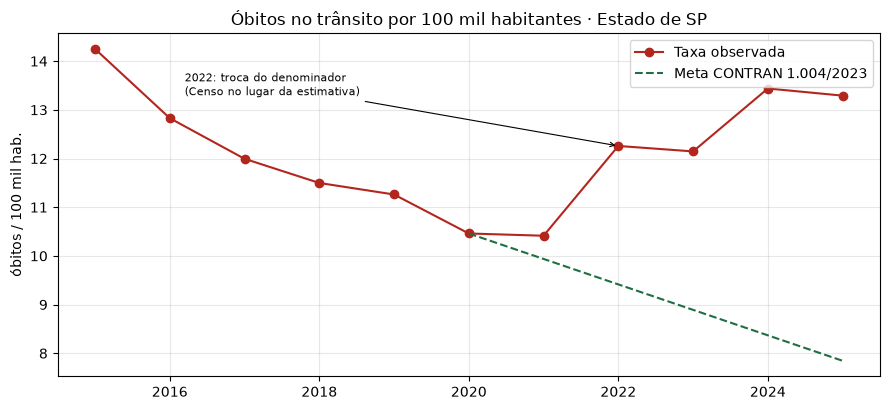

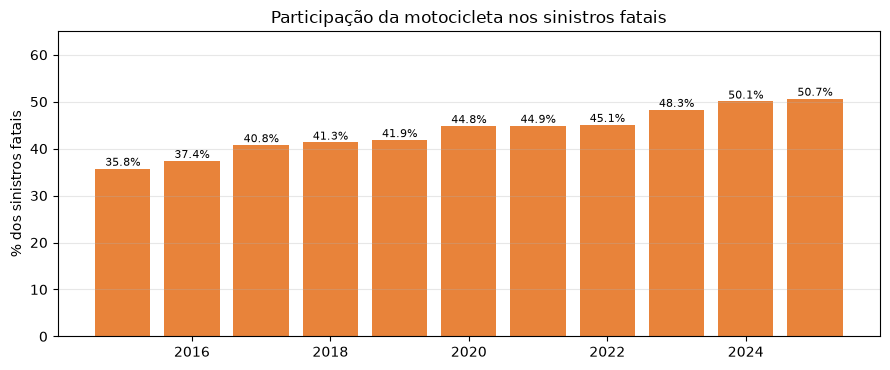

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
completos = anual.loc[2015:2025]
ax.plot(completos.index, completos["taxa_100k"], marker="o", color="#b3261e", label="Taxa observada")
ax.plot(completos.index, completos["meta_contran"], ls="--", color="#1f6f43", label="Meta CONTRAN 1.004/2023")
ax.set_title("Óbitos no trânsito por 100 mil habitantes · Estado de SP")
ax.set_ylabel("óbitos / 100 mil hab.")
ax.grid(alpha=.3)
ax.legend()
ax.annotate("2022: troca do denominador\n(Censo no lugar da estimativa)", xy=(2022, completos.loc[2022, "taxa_100k"]),
            xytext=(2016.2, 13.3), fontsize=8, arrowprops=dict(arrowstyle="->", lw=.8))
fig.tight_layout()
fig.savefig(FIG / "serie_taxa.png", dpi=130)
plt.show()

moto = cubo[cubo["ano"].between(2015, 2025)].groupby(["ano", "moto"])["sinistros_fatais"].sum().unstack()
part = moto["Com motocicleta"] / moto.sum(axis=1) * 100
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(part.index, part.values, color="#e8833a")
for x, y in part.items():
    ax.text(x, y + .6, f"{y:.1f}%", ha="center", fontsize=8)
ax.set_title("Participação da motocicleta nos sinistros fatais")
ax.set_ylabel("% dos sinistros fatais")
ax.set_ylim(0, 65)
ax.grid(axis="y", alpha=.3)
fig.tight_layout()
fig.savefig(FIG / "moto_participacao.png", dpi=130)
plt.show()

## 4. Análise preditiva (conteúdo da Parte 2)

**Problema:** classificação binária — dado um sinistro registrado, estimar a probabilidade de ele ser **fatal**.
**Por que importa:** a fiscalização e a engenharia de tráfego não conseguem agir em todos os pontos; um modelo de risco de
letalidade ordena onde a mesma ação salva mais vidas e explica *quais combinações de condições* tornam um sinistro letal,
complementando os indicadores descritivos da Parte 1 (que mostram *onde* e *quando*, não *quanto cada fator pesa*).

**Target:** `fatal` = sinistro registrado como `SINISTRO FATAL`.
**Base:** sinistros (sem `NOTIFICACAO`) de 2019 em diante, quando a base passou a registrar também os não fatais.

**Pré-processamento (vazamentos mapeados na Parte 1):**
1. Remover `tipo_registro` e todas as `qtd_gravidade_*` (são o desfecho).
2. Remover `tp_sinistro_colisao_traseira` (100% vazia).
3. Remover as linhas com `turno` ou `tipo_via` = `NAO DISPONIVEL`: a própria ausência marca o fluxo de registro de sinistro
   fatal (100% e 98% de fatais), então o modelo aprenderia o fluxo de cadastro e não o risco.
4. Conferir o mesmo efeito nas demais categorias `NAO DISPONIVEL` antes de decidir mantê-las.
5. `qtd_*` ausente = 0 (não envolvido); flags `tp_sinistro_*` = 1 quando `S`.

In [5]:
base = sin[(sin["tipo_registro"] != "NOTIFICACAO") & (sin["ano_sinistro"] >= 2019)].copy()
print(f"Base de modelagem antes da limpeza: {len(base):,} linhas, {base['fatal'].mean():.2%} fatais")
for col in ["turno", "tipo_via", "tipo_local", "tp_sinistro_primario", "administracao", "circunscricao"]:
    nd = base[col].fillna("NAO DISPONIVEL").eq("NAO DISPONIVEL")
    if nd.any():
        print(f"  {col} = NAO DISPONIVEL: {nd.sum():>7,} linhas, {base.loc[nd, 'fatal'].mean():.1%} fatais")
nd_flag = base["tp_sinistro_nao_disponivel"].eq("S")
print(f"  tp_sinistro_nao_disponivel = S: {nd_flag.sum():,} linhas, {base.loc[nd_flag, 'fatal'].mean():.1%} fatais")

Base de modelagem antes da limpeza: 929,731 linhas, 4.20% fatais
  turno = NAO DISPONIVEL:   1,822 linhas, 100.0% fatais
  tipo_via = NAO DISPONIVEL:   2,208 linhas, 98.4% fatais
  tipo_local = NAO DISPONIVEL: 158,410 linhas, 1.0% fatais
  tp_sinistro_primario = NAO DISPONIVEL:  11,625 linhas, 0.0% fatais
  administracao = NAO DISPONIVEL:  16,401 linhas, 13.9% fatais
  circunscricao = NAO DISPONIVEL:   5,539 linhas, 39.2% fatais
  tp_sinistro_nao_disponivel = S: 11,625 linhas, 0.0% fatais


In [6]:
base = base[(base["turno"] != "NAO DISPONIVEL") & (base["tipo_via"] != "NAO DISPONIVEL")].copy()
base["hora"] = pd.to_numeric(base["hora_sinistro"].str.slice(0, 2), errors="coerce").fillna(-1).astype(int)
cat = ["dia_da_semana", "turno", "tipo_via", "tipo_local", "regiao_administrativa", "administracao",
       "circunscricao", "tp_sinistro_primario"]
qtd = ["qtd_pedestre", "qtd_bicicleta", "qtd_motocicleta", "qtd_automovel", "qtd_onibus", "qtd_caminhao",
       "qtd_veic_outros", "qtd_veic_nao_disponivel"]
flags = [c for c in sin.columns if c.startswith("tp_sinistro_") and c not in
         ("tp_sinistro_primario", "tp_sinistro_colisao_traseira", "tp_sinistro_nao_disponivel")]
num = ["mes_sinistro", "hora"] + qtd + flags
for c in cat:
    base[c] = base[c].fillna("NAO DISPONIVEL").astype(str)
base[qtd] = base[qtd].fillna(0)
for c in flags:
    base[c] = base[c].eq("S").astype(int)
X, y = base[cat + num], base["fatal"]
print(f"Base final: {len(X):,} linhas, {y.mean():.2%} fatais | {len(cat)} categóricas + {len(num)} numéricas")
print("Removido como vazamento também: tp_sinistro_nao_disponivel (ausência de classificação do tipo de sinistro).")

Base final: 926,282 linhas, 3.84% fatais | 8 categóricas + 22 numéricas
Removido como vazamento também: tp_sinistro_nao_disponivel (ausência de classificação do tipo de sinistro).


**Separação treino/teste:** 80/20 estratificada pelo alvo, semente 42. Para caber no tempo de treino da rede neural, os
modelos treinam com uma amostra estratificada de 250 mil linhas do conjunto de treino; o teste usa **todo** o conjunto de
teste (20% da base), nunca visto no treino.

In [7]:
from sklearn.model_selection import train_test_split
X_tr_full, X_te, y_tr_full, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, _, y_tr, _ = train_test_split(X_tr_full, y_tr_full, train_size=250_000, stratify=y_tr_full, random_state=42)
print(f"Treino: {len(X_tr):,} ({y_tr.mean():.2%} fatais) | Teste: {len(X_te):,} ({y_te.mean():.2%} fatais)")

Treino: 250,000 (3.84% fatais) | Teste: 185,257 (3.84% fatais)


### Três modelos
1. **Regressão logística** (scikit-learn), com one-hot e padronização, `class_weight="balanced"`.
2. **LightGBM** (árvores com boosting de gradiente), `is_unbalance=True`.
3. **Rede neural profunda** — perceptron multicamadas (scikit-learn `MLPClassifier`) com 3 camadas ocultas (128, 64, 32), ReLU,
   Adam e parada antecipada.

In [8]:
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat),
                          ("num", StandardScaler(), num)])
modelos = {
    "Regressão logística": Pipeline([("prep", prep), ("m", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "LightGBM": None,
    "Rede neural (MLP 128-64-32)": Pipeline([("prep", prep), ("m", MLPClassifier(hidden_layer_sizes=(128, 64, 32),
                                              early_stopping=True, max_iter=60, random_state=42))]),
}
X_tr_lgb, X_te_lgb = X_tr.copy(), X_te.copy()
for c in cat:
    tipos = pd.CategoricalDtype(sorted(X[c].unique()))
    X_tr_lgb[c], X_te_lgb[c] = X_tr_lgb[c].astype(tipos), X_te_lgb[c].astype(tipos)

prob, tempos = {}, {}
for nome, modelo in modelos.items():
    t0 = time.time()
    if nome == "LightGBM":
        modelo = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, is_unbalance=True,
                                    random_state=42, verbose=-1)
        modelo.fit(X_tr_lgb, y_tr)
        modelos[nome] = modelo
        prob[nome] = modelo.predict_proba(X_te_lgb)[:, 1]
    else:
        modelo.fit(X_tr, y_tr)
        prob[nome] = modelo.predict_proba(X_te)[:, 1]
    tempos[nome] = time.time() - t0
    print(f"{nome}: treinado em {tempos[nome]:.0f} s")

Regressão logística: treinado em 6 s


LightGBM: treinado em 4 s


Rede neural (MLP 128-64-32): treinado em 50 s


### Avaliação e comparação
Com 4% de positivos, acurácia engana (prever "não fatal" sempre dá 96%). As métricas usadas:
- **ROC-AUC** e **PR-AUC** (precisão média): qualidade da ordenação por risco, independente de limiar.
- **Recall no top 10%**: fração dos sinistros fatais que estão entre os 10% de maior risco segundo o modelo — a pergunta
  operacional ("se olharmos só para os 10% mais arriscados, quantas mortes estão ali?").
- Precisão, recall e F1 no limiar que maximiza o F1.

In [9]:
linhas, curvas_roc, curvas_pr = [], [], []
for nome, p in prob.items():
    corte_top10 = np.quantile(p, 0.9)
    pr, rc, lim = precision_recall_curve(y_te, p)
    f1s = 2 * pr * rc / np.clip(pr + rc, 1e-9, None)
    i = int(np.nanargmax(f1s[:-1]))
    pred = (p >= lim[i]).astype(int)
    linhas.append({"modelo": nome, "roc_auc": roc_auc_score(y_te, p), "pr_auc": average_precision_score(y_te, p),
                   "recall_top10": y_te[p >= corte_top10].sum() / y_te.sum(),
                   "limiar_f1": lim[i], "precisao": precision_score(y_te, pred), "recall": recall_score(y_te, pred),
                   "f1": f1_score(y_te, pred), "tempo_treino_s": tempos[nome]})
    fpr, tpr, _ = roc_curve(y_te, p)
    sel = np.linspace(0, len(fpr) - 1, 200).astype(int)
    curvas_roc.append(pd.DataFrame({"modelo": nome, "fpr": fpr[sel], "tpr": tpr[sel]}))
    sel = np.linspace(0, len(rc) - 1, 200).astype(int)
    curvas_pr.append(pd.DataFrame({"modelo": nome, "recall": rc[sel], "precisao": pr[sel]}))
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    linhas[-1].update({"vn": tn, "fp": fp, "fn": fn, "vp": tp})
metricas = pd.DataFrame(linhas).sort_values("pr_auc", ascending=False)
metricas.to_csv(SAIDA / "metricas.csv", index=False)
pd.concat(curvas_roc).to_csv(SAIDA / "roc.csv", index=False)
pd.concat(curvas_pr).to_csv(SAIDA / "pr.csv", index=False)
metricas.round(3)

,modelo,roc_auc,pr_auc,recall_top10,limiar_f1,precisao,recall,f1,tempo_treino_s,vn,fp,fn,vp
2,Rede neural (MLP 128-64-32),0.933,0.553,0.723,0.286,0.595,0.463,0.521,49.810,175891,2243,3825,3298
1,LightGBM,0.933,0.549,0.724,0.872,0.567,0.467,0.513,3.517,175595,2539,3793,3330
0,Regressão logística,0.894,0.340,0.575,0.871,0.331,0.345,0.338,6.163,173168,4966,4666,2457


In [10]:
lgbm = modelos["LightGBM"]
imp = (pd.DataFrame({"variavel": X_tr_lgb.columns, "importancia": lgbm.booster_.feature_importance("gain")})
         .sort_values("importancia", ascending=False))
imp["importancia"] = imp["importancia"] / imp["importancia"].sum() * 100
imp.head(15).to_csv(SAIDA / "importancias.csv", index=False)
imp.head(15).round(2)

,variavel,importancia
29,tp_sinistro_outros,16.40
3,tipo_local,10.52
21,tp_sinistro_colisao_lateral,10.35
5,administracao,6.55
4,regiao_administrativa,5.19
7,tp_sinistro_primario,5.00
9,hora,4.73
13,qtd_automovel,3.78
17,qtd_veic_nao_disponivel,2.93
20,tp_sinistro_colisao_frontal,2.80


### Risco previsto por cenário
A tabela abaixo cruza o risco médio previsto pelo LightGBM no conjunto de teste com a letalidade observada, para cada
combinação de tipo de via, turno, tipo de sinistro e presença de motocicleta. É o que a dashboard usa no simulador de
cenários: o usuário escolhe as condições e vê o risco estimado ao lado do observado.

In [11]:
cen = X_te[["tipo_via", "turno", "tp_sinistro_primario"]].copy()
cen["moto"] = np.where(X_te["qtd_motocicleta"] > 0, "Com motocicleta", "Sem motocicleta")
cen["risco_previsto"] = prob["LightGBM"]
cen["fatal"] = y_te.values
cenarios = (cen.groupby(["tipo_via", "turno", "tp_sinistro_primario", "moto"])
              .agg(sinistros=("fatal", "size"), letalidade_observada=("fatal", "mean"), risco_previsto=("risco_previsto", "mean"))
              .reset_index())
cenarios = cenarios[cenarios["sinistros"] >= 30]
cenarios.round(4).to_csv(SAIDA / "cenarios.csv", index=False)
print(f"{len(cenarios)} cenários com pelo menos 30 sinistros no teste")
cenarios.sort_values("letalidade_observada", ascending=False).head(8).round(3)

73 cenários com pelo menos 30 sinistros no teste


,tipo_via,turno,tp_sinistro_primario,moto,sinistros,letalidade_observada,risco_previsto
1,ESTRADAS E RODOVIAS,MADRUGADA,ATROPELAMENTO,Sem motocicleta,264,0.682,0.786
21,ESTRADAS E RODOVIAS,NOITE,ATROPELAMENTO,Sem motocicleta,741,0.499,0.713
11,ESTRADAS E RODOVIAS,MANHA,ATROPELAMENTO,Sem motocicleta,192,0.370,0.595
42,VIAS URBANAS,MADRUGADA,CHOQUE,Com motocicleta,648,0.292,0.687
20,ESTRADAS E RODOVIAS,NOITE,ATROPELAMENTO,Com motocicleta,210,0.286,0.600
31,ESTRADAS E RODOVIAS,TARDE,ATROPELAMENTO,Sem motocicleta,211,0.284,0.605
0,ESTRADAS E RODOVIAS,MADRUGADA,ATROPELAMENTO,Com motocicleta,36,0.250,0.652
4,ESTRADAS E RODOVIAS,MADRUGADA,COLISAO,Com motocicleta,566,0.196,0.467


### Gráfico estático da comparação

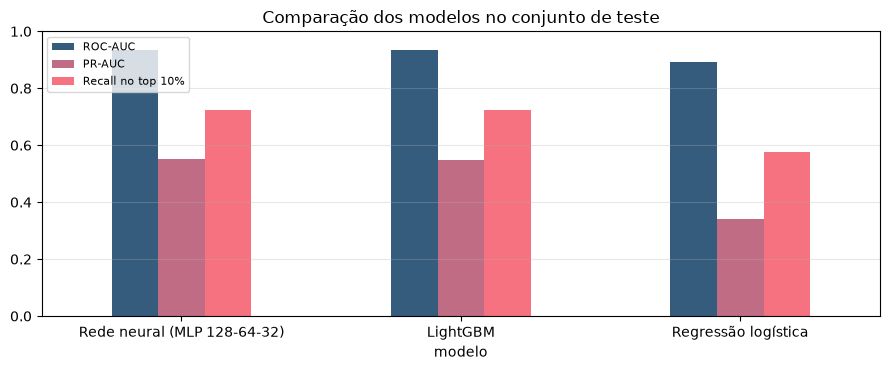

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
m = metricas.set_index("modelo")[["roc_auc", "pr_auc", "recall_top10"]]
m.plot.bar(ax=ax, color=["#355c7d", "#c06c84", "#f67280"], rot=0)
ax.set_title("Comparação dos modelos no conjunto de teste")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=.3)
ax.legend(["ROC-AUC", "PR-AUC", "Recall no top 10%"], loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "comparacao_modelos.png", dpi=130)
plt.show()

## 5. Como a análise preditiva complementa os indicadores da Parte 1

Os KPIs da Parte 1 dizem **quanto** se morre e **onde/quando** (taxa por 100 mil, participação da motocicleta, madrugada,
rodovias, interior). O modelo acrescenta duas coisas que um indicador agregado não dá:
1. **Peso relativo de cada fator controlando os demais** (importância das variáveis): separa o efeito da motocicleta do efeito
   da rodovia, que aparecem misturados num gráfico de barras.
2. **Priorização**: a métrica de recall no top 10% mostra quantos sinistros fatais se concentram na fração mais arriscada,
   o que transforma o diagnóstico em uma lista de ação (fiscalização, engenharia de via, campanhas por perfil de cenário).

**Limitações:** o modelo usa só o que o boletim registra (sem velocidade, uso de capacete, álcool ou condição da via); a
fatalidade depende também do tempo de socorro, que a base não traz; e a mudança de critério de registro de 2025 (Parte 1,
seção 5.2) altera a proporção entre classes no tempo. Por isso o resultado é usado para **ordenar risco**, não como
probabilidade calibrada de morte.

In [13]:
resumo = {
    "base_modelagem_linhas": int(len(X)), "base_modelagem_taxa_fatal": float(y.mean()),
    "treino_linhas": int(len(X_tr)), "teste_linhas": int(len(X_te)),
    "taxa_2020": float(base_2020), "taxa_2025": float(anual.loc[2025, "taxa_100k"]),
    "meta_2025": float(anual.loc[2025, "meta_contran"]), "vidas_acima_meta_2025": float(excesso_2025),
}
(SAIDA / "resumo.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(resumo, ensure_ascii=False, indent=2))
print(sorted(p.name for p in SAIDA.iterdir()), sorted(p.name for p in FIG.iterdir()))

{
  "base_modelagem_linhas": 926282,
  "base_modelagem_taxa_fatal": 0.03844941389339316,
  "treino_linhas": 250000,
  "teste_linhas": 185257,
  "taxa_2020": 10.460293303426948,
  "taxa_2025": 13.291581203607905,
  "meta_2025": 7.845219977570211,
  "vidas_acima_meta_2025": 2509.78134192385
}
['anual.csv', 'cenarios.csv', 'cubo.csv', 'importancias.csv', 'metricas.csv', 'municipios.csv', 'municipios_sp.geojson', 'pop_regiao.csv', 'pr.csv', 'resumo.json', 'roc.csv'] ['comparacao_modelos.png', 'moto_participacao.png', 'serie_taxa.png']
